# Hierarchical Clustering - UPGMA

---
## Learning Objectives

1. Implement a distance-based phylogeny neighbor joining algorithm
1. Understanding of hierarchical clustering
1. Manipulation of arrays and lists in Python


---
## Imports
You will need to install a two new packages to properly render your phylogenetic trees. Using your preferred package manager, install both [`biopython`](https://biopython.org/) and `matplotlib` into your virtual environments.

For example:
```bash
$ micromamba create -n module06 -c bioconda -c conda-forge python numpy matplotlib biopython
```

In [1]:
from typing import List, Tuple, Dict
from io import StringIO
import math

import matplotlib.pyplot as plt
from Bio import Phylo
import numpy as np

---
## Background

Today we will implement a distance-based phylogenetic tree construction method using the Neighbor-Joining (NJ) algorithm and Smith-Waterman local alignment scores. Unlike UPGMA (Unweighted Pair Group Method using Arithmetic averages), NJ produces unrooted trees and does not assume a constant evolutionary rate across lineages, making it more biologically realistic for analyzing sequence relationships.

We will use HIV-1 reverse transcriptase sequences to construct our phylogenetic tree. The Smith-Waterman algorithm will be used to generate pairwise local alignment scores, which will then be converted into distances for tree construction. This approach is particularly suitable for HIV sequence analysis as it:
1. Handles sequence variations effectively through local alignment
2. Accounts for potential rate heterogeneity across different viral strains
3. Does not assume a molecular clock

The ultimate output will be an unrooted phylogenetic tree representing the evolutionary relationships between the HIV-1 sequences, visualized using the ete3 library. This method provides insights into viral diversity and evolutionary patterns while avoiding the assumptions of simpler hierarchical clustering approaches.

The key innovations of this implementation are:
- Use of Smith-Waterman for sensitive local alignment scoring
- Implementation of Neighbor-Joining for unrooted tree construction
- More biologically realistic evolutionary model

## Neighbor-Joining Algorithm

**Input**: Distance matrix $D$ for $n$ sequences

**Initialization**:
- Let $n$ be the number of sequences
- Assign each sequence $i$ to its own leaf node
- Initialize tree $T$ with leaf nodes

**Iteration**:
While $n > 2$:
1. Calculate Q-matrix where:
   $Q(i,j) = (n-2)d(i,j) - \sum_{k=1}^n d(i,k) - \sum_{k=1}^n d(j,k)$

2. Find pair $(i,j)$ with minimum $Q(i,j)$

3. Calculate branch lengths:
   $d_i = \frac{d(i,j) + (r_i - r_j)/(n-2)}{2}$
   $d_j = d(i,j) - d_i$
   where $r_i = \sum_{k=1}^n d(i,k)$

4. Create new node $k$
   - Add branches from $k$ to $i$ and $j$ with lengths $d_i$ and $d_j$

5. Update distances to remaining nodes $x$:
   $d(k,x) = \frac{d(i,x) + d(j,x) - d(i,j)}{2}$

6. Remove nodes $i$ and $j$
7. Add node $k$ to active nodes
8. $n = n - 1$

**Termination**:
When $n = 2$ with remaining nodes $i$ and $j$:
- Add final branch between $i$ and $j$ with length $d(i,j)$
- Return unrooted tree $T$

---
## Distance metrics for comparing sequences

### Smith-Waterman
This was previously implemented. Feel free to import if you know how...or Copy & Paste.



In [2]:
def read_fasta(filename: str) -> Dict[str, str]:
    """Reads sequences from FASTA file.

    Args:
        filename (str): Path to FASTA file containing HIV RT sequences

    Returns:
        Dict[str, str]: Dictionary mapping sequence IDs to sequences
    """
    # Set up an empty dictionary {name: sequence} and "no current name yet"
    sequences = {}
    current_name = None

    # Read the file one line at a time
    with open(filename) as f:
        for line in f:
            # Remove the newline and spaces at both ends
            line = line.strip()
            # Blank line: nothing to read, skip it
            if not line:
                continue
            # Header line: the name is the LAST word (e.g. "DM1", "P1")
            elif line.startswith(">"):
                current_name = line.split()[-1]
                # Start an empty sequence for this name
                sequences[current_name] = ""
            # Sequence line: glue it onto the current sequence (each sequence spans 4 lines)
            else:
                sequences[current_name] = sequences[current_name] + line

    # Give back the dictionary
    return sequences

In [3]:
def raw_smith_waterman(
    seq1: str,
    seq2: str,
    match_score: float = 2.0,
    mismatch_penalty: float = -1.0,
    gap_penalty: float = -1.0
) -> float:
    """Raw Smith-Waterman score (adapted from our Project 05 code).

    Same fill loop and cell rule as Project 05's cal_score(); the traceback,
    printing and random tie-break are removed because only the score is needed.
    """
    # Set up the score grid; +1 adds the zero border row and column
    score_matrix = [[0.0] * (len(seq2) + 1) for _ in range(len(seq1) + 1)]

    # Walk through each cell, row by row, top to bottom, left to right
    for i in range(1, len(seq1) + 1):
        for j in range(1, len(seq2) + 1):
            # Look up the cell's two letters (i-1, j-1 because of the border)
            if seq1[i - 1] == seq2[j - 1]:
                letter_score = match_score
            else:
                letter_score = mismatch_penalty
            # Option 1: up-left box + match/mismatch score
            diag = score_matrix[i - 1][j - 1] + letter_score
            # Option 2: box above + gap penalty
            up = score_matrix[i - 1][j] + gap_penalty
            # Option 3: box to the left + gap penalty
            left = score_matrix[i][j - 1] + gap_penalty
            # Option 4: 0 = start over (this is what makes it LOCAL); keep the biggest
            score_matrix[i][j] = max(0.0, diag, up, left)

    # The score is the BIGGEST cell anywhere in the grid
    return max(max(row) for row in score_matrix)

### Version A: simple normalization
Normalized by the geometric mean of the two self-scores, then flip it into a distance.


In [4]:
def smith_waterman_simple(
    sequence1: str,
    sequence2: str,
    match_score: float = 2.0,
    mismatch_penalty: float = -1.0,
    gap_penalty: float = -1.0
) -> float:
    """Normalized similarity (Version A). 1.0 for identical sequences.

    Examples:
        >>> smith_waterman_simple("ACGT", "ACGT")
        1.0
    """
    scoring = (match_score, mismatch_penalty, gap_penalty)

    # Raw score for the pair
    s_ab = raw_smith_waterman(sequence1, sequence2, *scoring)

    # Each sequence's perfect score (aligned with itself)
    s_aa = raw_smith_waterman(sequence1, sequence1, *scoring)
    s_bb = raw_smith_waterman(sequence2, sequence2, *scoring)

    # Compare to perfect -> 1.0 for identical sequences
    return s_ab / math.sqrt(s_aa * s_bb)

In [5]:
def build_distance_matrix_simple(sequences: Dict[str, str]) -> Tuple[np.ndarray, List[str]]:
    """Distance matrix with Version A: d = 1 - normalized similarity."""
    # List the names, count them, and make an N x N table of 0s (the diagonal stays 0)
    ids = list(sequences)
    N = len(ids)
    distance = np.zeros((N, N))

    # Every pair once (j starts after i, because the table is symmetric)
    for i in range(N):
        for j in range(i + 1, N):
            # How alike (normalized similarity)
            similarity = smith_waterman_simple(sequences[ids[i]], sequences[ids[j]])

            # Flip "how alike" into "how different"
            d = 1 - similarity

            # A distance is never negative (this also turns -0.0 into 0.0)
            if d <= 0:
                d = 0.0

            # Write it in BOTH halves (symmetry)
            distance[i][j] = d
            distance[j][i] = d

    # Give back the table and the names, in the same order as the rows
    return distance, ids

### Version B: Feng & Doolittle (1987)
The assignment points to Feng & Doolittle (1987): normalize against the self-scores **and** against shuffled sequences, then take a log.
Formula and code: Cited in README, provided by AI by prompting the "Feng & Doolittle (1987) normalization formula" - has not been checked against the actual paper.\
Our choices (suggsted by AI): 10 shuffles, seed 42, and replacing $S_{eff} \le 0$ with $10^{-6}$ so the log never breaks.

In [6]:
def random_score(
    sequence1: str,
    sequence2: str,
    match_score: float = 2.0,
    mismatch_penalty: float = -1.0,
    gap_penalty: float = -1.0,
    num_shuffles: int = 10,
    seed: int = 42
) -> float:
    """How many points two sequences get by pure luck (S_rand)."""
    scoring = (match_score, mismatch_penalty, gap_penalty)

    # Set up a random shuffler with a seed, so the shuffles are the same every run
    rng = np.random.default_rng(seed)

    # Shuffle both sequences (same letters, random order), score them, and repeat
    total = 0.0
    for _ in range(num_shuffles):
        shuffled1 = "".join(rng.permutation(list(sequence1)))
        shuffled2 = "".join(rng.permutation(list(sequence2)))
        total = total + raw_smith_waterman(shuffled1, shuffled2, *scoring)

    # The luck score is the average over all shuffles
    return total / num_shuffles

In [7]:
def smith_waterman_fd(
    sequence1: str,
    sequence2: str,
    match_score: float = 2.0,
    mismatch_penalty: float = -1.0,
    gap_penalty: float = -1.0,
    num_shuffles: int = 10,
    seed: int = 42
) -> float:
    """Normalized similarity with luck taken out (Version B, S_eff). 1.0 for identical sequences.

    Examples:
        >>> smith_waterman_fd("ACGT", "ACGT")
        1.0
    """
    scoring = (match_score, mismatch_penalty, gap_penalty)

    # Real score for the pair (S_obs)
    s_obs = raw_smith_waterman(sequence1, sequence2, *scoring)

    # Perfect score: the AVERAGE of the two self-scores (S_max)
    s_max = (raw_smith_waterman(sequence1, sequence1, *scoring)
             + raw_smith_waterman(sequence2, sequence2, *scoring)) / 2

    # Luck score from shuffled copies (S_rand)
    s_rand = random_score(sequence1, sequence2, *scoring, num_shuffles, seed)

    # Stop if the perfect score is no better than luck (we can't divide by 0 or less)
    if s_max <= s_rand:
        raise ValueError("Perfect score is not better than the random score")

    # Take out the luck -> 1.0 for identical sequences
    return (s_obs - s_rand) / (s_max - s_rand)

In [8]:
def build_distance_matrix_fd(sequences: Dict[str, str]) -> Tuple[np.ndarray, List[str]]:
    """Distance matrix with Version B: d = -ln(S_eff)."""
    # List the names, count them, and make an N x N table of 0s (the diagonal stays 0)
    ids = list(sequences)
    N = len(ids)
    distance = np.zeros((N, N))

    # Every pair once (j starts after i, because the table is symmetric)
    for i in range(N):
        for j in range(i + 1, N):
            # How alike, with luck taken out (S_eff)
            similarity = smith_waterman_fd(sequences[ids[i]], sequences[ids[j]])

            # The log only works on numbers above 0
            # (a pair that scores no better than luck gets a tiny similarity -> a big distance)
            if similarity <= 0:
                similarity = 1e-6

            # Flip "how alike" into "how different" with -ln
            d = -math.log(similarity)

            # A distance is never negative (this also turns -0.0 into 0.0)
            if d <= 0:
                d = 0.0

            # Write it in BOTH halves (symmetry)
            distance[i][j] = d
            distance[j][i] = d

    # Give back the table and the names, in the same order as the rows
    return distance, ids

### Check the properties of a distance
A distance must follow four rules. The next cell checks each rule for both versions:
- **Identity:** every sequence is 0 away from itself (the diagonal is all 0)
- **Symmetry:** the distance from a to b equals the distance from b to a
- **Non-negativity:** no distance is below 0
- **Triangle inequality:** going directly is never longer than going through a third sequence\
Code for this cell below is provided by AI, I had provided it the rules above, taken from Module 06 slides

In [12]:
sequences = read_fasta("data/lafayette_SARS_RT.fasta")
mat_simple, ids = build_distance_matrix_simple(sequences)
mat_fd, _ = build_distance_matrix_fd(sequences)
def check_distance_properties(mat, name):
    n = len(mat)
    tol = 1e-12  # ignore tiny rounding differences

    # Identity: the diagonal is all 0
    identity = all(abs(mat[i][i]) <= tol for i in range(n))

    # Symmetry: mat[i][j] equals mat[j][i] for every pair
    symmetry = all(abs(mat[i][j] - mat[j][i]) <= tol for i in range(n) for j in range(n))

    # Non-negativity: nothing below 0
    non_negative = all(mat[i][j] >= -tol for i in range(n) for j in range(n))

    # Triangle inequality: count every (i, j, k) where i->k directly is longer than i->j->k
    violations = sum(1 for i in range(n) for j in range(n) for k in range(n)
                     if mat[i][k] > mat[i][j] + mat[j][k] + tol)

    print(f"{name}")
    print(f"  Identity:            {'OK' if identity else 'FAIL'}")
    print(f"  Symmetry:            {'OK' if symmetry else 'FAIL'}")
    print(f"  Non-negativity:      {'OK' if non_negative else 'FAIL'}")
    print(f"  Triangle inequality: {violations} violations out of {n ** 3} checks")


check_distance_properties(mat_simple, "Version A (simple)")
check_distance_properties(mat_fd, "Version B (Feng & Doolittle)")
print(mat_simple)

Version A (simple)
  Identity:            OK
  Symmetry:            OK
  Non-negativity:      OK
  Triangle inequality: 0 violations out of 8000 checks
Version B (Feng & Doolittle)
  Identity:            OK
  Symmetry:            OK
  Non-negativity:      OK
  Triangle inequality: 114 violations out of 8000 checks
[[0.         0.00655022 0.04585153 0.05240175 0.05240175 0.14628821
  0.08733624 0.03930131 0.11353712 0.09388646 0.06550218 0.09170306
  0.03275109 0.05458515 0.03930131 0.11135371 0.05240175 0.05240175
  0.15283843 0.05895197]
 [0.00655022 0.         0.03930131 0.04585153 0.04585153 0.13973799
  0.08078603 0.03275109 0.1069869  0.08733624 0.05895197 0.08515284
  0.02620087 0.04803493 0.03275109 0.10480349 0.04585153 0.04585153
  0.14628821 0.05240175]
 [0.04585153 0.03930131 0.         0.01310044 0.01310044 0.13973799
  0.10043668 0.05895197 0.12663755 0.11353712 0.07860262 0.09825328
  0.04585153 0.06768559 0.05895197 0.0720524  0.0720524  0.0720524
  0.16593886 0.07860262

In [11]:
def neighbor_joining(
        distance_matrix: np.ndarray,
        labels: List[str],
        seed: int = 42
) -> str:
    """Implements Neighbor-Joining algorithm for phylogenetic tree construction.

    Args:
        distance_matrix (np.ndarray): Distance matrix from Smith-Waterman scores
        labels (List[str]): Sequence identifiers
        seed (int): Seed for the random tie-break, so ties are broken the same way every run

    Returns:
        str: Newick format tree string
    """

    #1. Input:
    # Make a copy of the distance table so the original stays the same
    D = np.array(distance_matrix, dtype=float)
    # Set up a random picker with a seed, so ties are broken the same way every run
    rng = np.random.default_rng(seed)

    #2. Initialization:
    # Start with every sequence as its own leaf
    # Keep the names in the same order as the rows of D
    active = list(labels)
    # Start an empty tree
    # Each new node we create will remember the two nodes it joined and their branch lengths
    T = {}
    # Count how many nodes are left
    n = len(active)
    node_number = 0

    #3. Iteration:
    # Keep joining pairs until only 2 nodes are left
    while n > 2:

        # For each node, add up its distances to everyone else
        r = D.sum(axis=1)

        # Calculate Q for every pair (this finds who is close to each other, not just close to everyone)
        pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]
        Q = {(i, j): (n - 2) * D[i][j] - r[i] - r[j] for (i, j) in pairs}

        # Find the smallest Q
        best_Q = min(Q.values())

        # Find every pair that has that smallest Q (use "close to", because decimals are not stored exactly)
        tied_pairs = [pair for pair in pairs if math.isclose(Q[pair], best_Q, abs_tol=1e-12)]

        # If there is a tie, pick one pair at random
        i, j = tied_pairs[rng.integers(len(tied_pairs))]

        # Work out how long the branch is from the new node to i, and to j
        d_i = (D[i][j] + (r[i] - r[j]) / (n - 2)) / 2
        d_j = D[i][j] - d_i

        # A negative branch = 0
        if d_i <= 0:
            d_i = 0.0
        if d_j <= 0:
            d_j = 0.0

        # Make a new node k that joins i and j, and save its two branches in the tree
        node_number += 1
        k = f"node{node_number}"
        T[k] = [(active[i], d_i), (active[j], d_j)]

        # Work out the distance from the new node k to every other node x
        others = [x for x in range(n) if x != i and x != j]
        d_k = [(D[i][x] + D[j][x] - D[i][j]) / 2 for x in others]

        # Remove i and j from the table, and add k as the last row and column
        new_D = np.zeros((n - 1, n - 1))
        new_D[:-1, :-1] = D[np.ix_(others, others)]
        new_D[-1, :-1] = d_k
        new_D[:-1, -1] = d_k
        D = new_D

        # Do the same to the list of names, so names and rows still match
        active = [active[x] for x in others] + [k]

        # One fewer node is left now
        n = n - 1

    #4. Termination: Only 2 nodes are left: connect them with one last branch and write the tree as text
    return to_newick(T, active[0], active[1], D[0][1])

In [13]:
def node_string(T: dict, node: str) -> str:
    """Writes one node of tree T as Newick text (recursive)."""

    # If the node is a leaf (not in the tree dictionary), just write its name
    if node not in T:
        return node

    # Otherwise, write each of its two branches as "name:length"
    # If the other end is also a new node, write that one first (the function calls itself)
    parts = []
    for other_node, length in T[node]:
        parts.append(node_string(T, other_node) + ":" + f"{length:.6f}")

    # Put the two parts in brackets, separated by a comma
    return "(" + ",".join(parts) + ")"

In [14]:
def to_newick(T: dict, i: str, j: str, d_ij: float) -> str:
    """Adds the final branch between the last two nodes i and j and finishes the Newick text."""

    # Make sure i is the new node (swap them if i is a leaf and j is not)
    if i not in T and j in T:
        i, j = j, i

    # If both are leaves, there were only 2 sequences, so write them as a simple pair
    if i not in T:
        return "(" + i + ":" + f"{d_ij:.6f}" + "," + j + ":0);"

    # Write the two branches of node i
    parts = [node_string(T, other_node) + ":" + f"{length:.6f}" for other_node, length in T[i]]

    # Add the last branch to j as a third item
    parts.append(node_string(T, j) + ":" + f"{d_ij:.6f}")

    # Put everything in brackets and end with ";"
    return "(" + ",".join(parts) + ");"

In [15]:
def plot_tree(newick_tree: str) -> None:
    """Plots a phylogenetic tree from a Newick string using Biopython and Matplotlib.

    The tree is rendered in a rectangular layout with smaller leaf labels and
    added margins to reduce overlap between labels and branches.

    Args:
        newick_tree (str): Tree in Newick format

    Returns:
        None: Displays the plotted tree
    """
    handle = StringIO(newick_tree)
    tree = Phylo.read(handle, "newick")

    fig, ax = plt.subplots(figsize=(8, 10))

    Phylo.draw(
        tree,
        axes=ax,
        do_show=False,
        label_func=lambda clade: clade.name if clade.is_terminal() else None,
    )
    for text in ax.texts:
        text.set_fontsize(6)              # shrink labels
    ax.margins(x=0.1, y=0.05)             # extra padding around tree

    plt.tight_layout()
    plt.show()


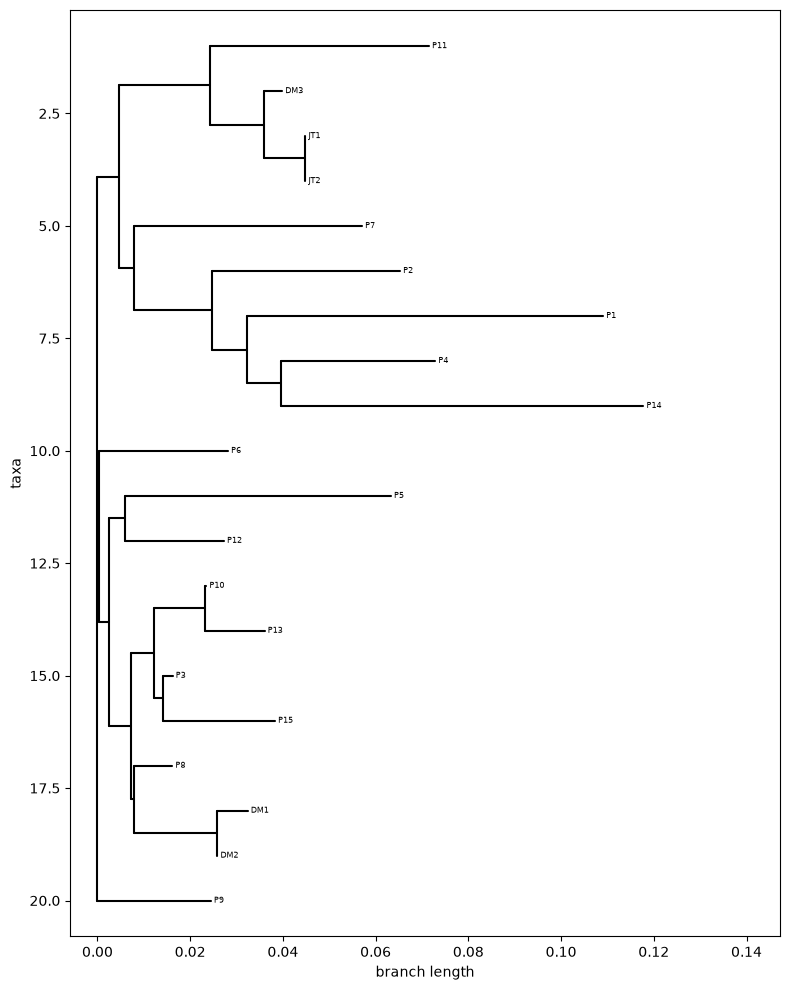

In [16]:
if __name__ == "__main__":
    # Read HIV RT sequences
    sequences = read_fasta("data/lafayette_SARS_RT.fasta")
    # Build distance matrix using Smith-Waterman
    dist_matrix, seq_ids = build_distance_matrix_simple(sequences)
    
    # Generate unrooted tree using Neighbor-Joining
    tree = neighbor_joining(dist_matrix, seq_ids)
    
    # Plot tree
    plot_tree(tree)